# Regresión Logística (Clasificación Binaria)

**Programa Especializado en IA · C-DAC Noida · ITEC · India 2026**

*Resuelto paso a paso — PhD (c) Luis Correa*

---
Cuando la respuesta es **sí/no** (0 o 1), no usamos regresión lineal sino **logística**. Ejemplo: ¿comprará un seguro de vida una persona según su **edad**?

## 1. El problema

Es un problema **binario**: solo hay dos resultados posibles (compra el seguro = 1, no lo compra = 0). La regresión logística usa la **función sigmoide** para devolver una **probabilidad** entre 0 y 1.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/insurance_data.csv')
df.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


Graficamos edad vs. compró_seguro. Se ve que las personas mayores tienden a comprar (1) y las jóvenes no (0).

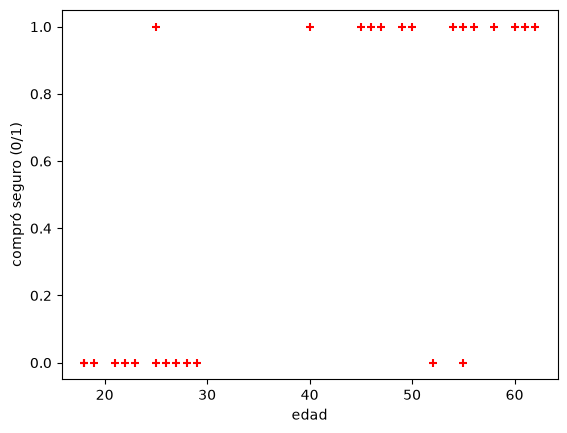

In [3]:
plt.scatter(df.age, df.bought_insurance, marker='+', color='red')
plt.xlabel('edad'); plt.ylabel('compró seguro (0/1)')
plt.show()

Separamos datos de entrenamiento (80%) y prueba, y definimos X (edad) e y (compró).

In [4]:
from sklearn.model_selection import train_test_split
X = df[['age']]
y = df.bought_insurance
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=10)

In [5]:
X_test

,age
7,60
5,56
18,19
21,26
11,28
1,25


Creamos y entrenamos el modelo de **regresión logística**.

In [6]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Predecimos sobre los datos de prueba (0 = no compra, 1 = compra).

In [7]:
y_predicted = model.predict(X_test)
y_predicted

array([1, 1, 0, 0, 0, 0])

`predict_proba` nos da la **probabilidad** de cada clase (no compra / compra). Así vemos la confianza del modelo.

In [8]:
model.predict_proba(X_test)

array([[0.07149837, 0.92850163],
       [0.10786034, 0.89213966],
       [0.88695424, 0.11304576],
       [0.78083769, 0.21916231],
       [0.73981335, 0.26018665],
       [0.79952571, 0.20047429]])

El **score** mide el porcentaje de aciertos en el conjunto de prueba.

In [9]:
model.score(X_test, y_test)

1.0

Los parámetros aprendidos: **m** (`coef_`) y **b** (`intercept_`) de la ecuación `y = m*x + b`.

In [10]:
model.coef_

array([[0.112778]])

In [11]:
model.intercept_

array([-4.20278276])

## 2. La función sigmoide a mano

La regresión logística aplica la **sigmoide** al resultado lineal `z = m*x + b`:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Comprobamos la predicción nosotros mismos usando los coeficientes del modelo.

In [12]:
import math
def sigmoid(z):
    return 1 / (1 + math.exp(-z))

In [13]:
def prediction_function(age):
    z = model.coef_[0][0] * age + model.intercept_[0]
    y = sigmoid(z)
    return y

Para una persona de **54 años**: probabilidad alta de comprar (> 0.5).

In [14]:
prediction_function(54)

0.8684393052145238

Para una persona de **22 años**: probabilidad baja de comprar (< 0.5).

In [15]:
prediction_function(22)

0.1516566069252542

Dibujamos la **curva sigmoide** del modelo sobre los datos reales.

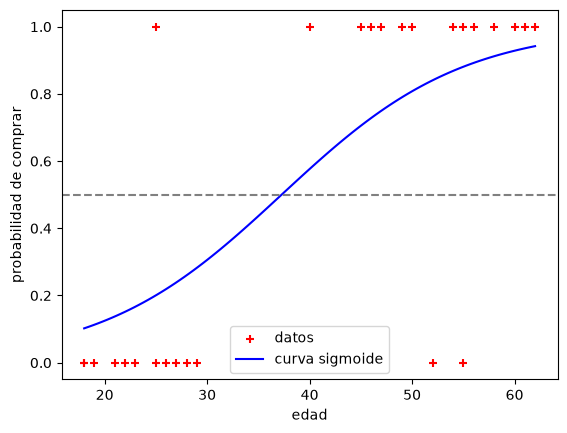

In [16]:
import numpy as np
edades = np.linspace(df.age.min(), df.age.max(), 100)
probs = [prediction_function(a) for a in edades]
plt.scatter(df.age, df.bought_insurance, marker='+', color='red', label='datos')
plt.plot(edades, probs, color='blue', label='curva sigmoide')
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('edad'); plt.ylabel('probabilidad de comprar')
plt.legend(); plt.show()

## Ejercicio práctico

**Enunciado (del curso):** Con el dataset de **retención de empleados** (`HR_comma_sep.csv`):
1. Explorar qué variables influyen en que un empleado **se vaya** (`left`).
2. Graficar el impacto del **salario** y del **departamento** en la retención.
3. Construir un modelo de **regresión logística** con las variables elegidas.
4. Medir la **precisión** del modelo.

**Paso 1.** Cargamos los datos (casi 15,000 empleados).

In [17]:
df_hr = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/HR_comma_sep.csv')
df_hr.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


**Paso 2.** Exploramos: comparamos el promedio de cada variable entre los que se quedaron (left=0) y los que se fueron (left=1).

In [18]:
df_hr.groupby('left').mean(numeric_only=True)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years
left,,,,,,,
0,0.666810,0.715473,3.786664,199.060203,3.380032,0.175009,0.026251
1,0.440098,0.718113,3.855503,207.419210,3.876505,0.047326,0.005321


Se observa que quienes se van tienen **menor satisfacción**, menos promociones y patrones distintos de horas. Graficamos el impacto del **salario** en la salida.

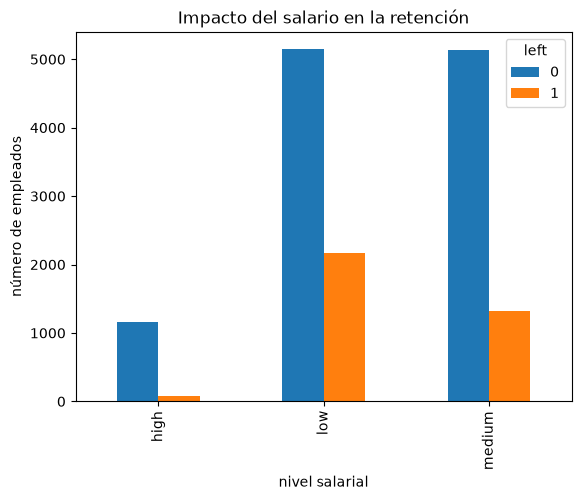

In [19]:
pd.crosstab(df_hr.salary, df_hr.left).plot(kind='bar')
plt.title('Impacto del salario en la retención')
plt.xlabel('nivel salarial'); plt.ylabel('número de empleados')
plt.show()

Y el impacto del **departamento**.

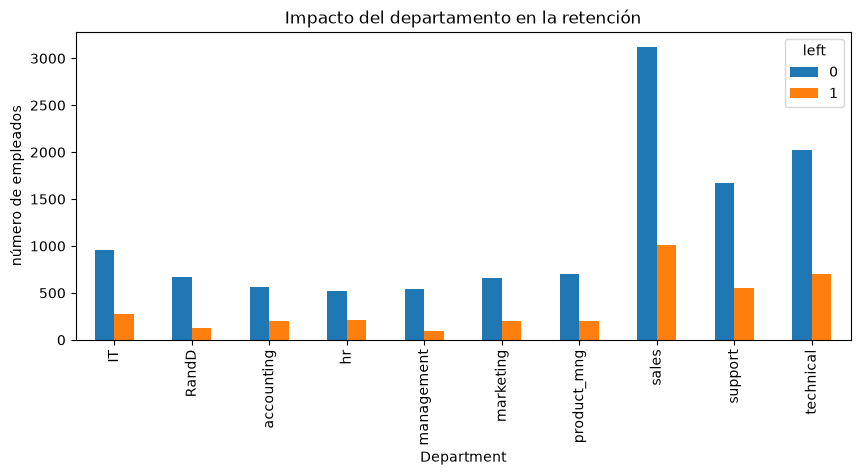

In [20]:
pd.crosstab(df_hr.Department, df_hr.left).plot(kind='bar', figsize=(10,4))
plt.title('Impacto del departamento en la retención')
plt.ylabel('número de empleados')
plt.show()

**Paso 3.** Elegimos las variables con impacto claro y convertimos el salario (texto) a columnas 0/1 con one-hot.

In [21]:
subset = df_hr[['satisfaction_level','average_montly_hours','promotion_last_5years','salary']]
salary_dummies = pd.get_dummies(subset.salary, prefix='salary')
df_model = pd.concat([subset.drop('salary', axis='columns'), salary_dummies], axis='columns')
df_model.head()

,satisfaction_level,average_montly_hours,promotion_last_5years,salary_high,salary_low,salary_medium
0,0.38,157,0,False,True,False
1,0.80,262,0,False,False,True
2,0.11,272,0,False,False,True
3,0.72,223,0,False,True,False
4,0.37,159,0,False,True,False


**Paso 4.** Entrenamos la regresión logística y medimos la precisión.

In [22]:
X_hr = df_model
y_hr = df_hr.left
Xtr, Xte, ytr, yte = train_test_split(X_hr, y_hr, test_size=0.2, random_state=10)

model_hr = LogisticRegression(max_iter=1000)
model_hr.fit(Xtr, ytr)
print(f"Precisión del modelo de retención: {model_hr.score(Xte, yte):.4f}")

Precisión del modelo de retención: 0.7707


**Conclusión:** la **satisfacción** del empleado es la variable más decisiva para predecir si se va. El modelo de regresión logística alcanza una precisión cercana al 77-78%, suficiente para identificar patrones de rotación y apoyar decisiones de recursos humanos.